In [1]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pyarrow.parquet as pq
from torch.utils.data import DataLoader, IterableDataset
import math
import random
from utils.models import *
from utils.train_test import *
from utils.dna_dataset_2 import DaskCuDFIntegerDataset, ParquetCPUDataset
import fsspec
torch.set_float32_matmul_precision('high')
# --- 1. Configurações e Imports dos Modelos ---
# (Certifique-se de que as classes dos modelos estejam definidas ou importadas aqui)
# from models import convnext_tiny_1d, resnet50_1d 

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES = 13683
MAX_LEN = 512
NUM_FEATURES = 4
BATCH_SIZE = 2048 # Pode ser maior no teste (apenas inferência)
base_type_data = "species"
# Caminhos dos seus Melhores Modelos (Atualize estes caminhos!)
PATH_RESNET = f"../cnn_kraken_{base_type_data}/checkpoints/best_resnet_classifier__fast_phase4.pt" # Exemplo: seu melhor checkpoint da ResNet
PATH_CONVNEXT_zero = f"./checkpoint_{base_type_data}_conv_zero/best_convnext_phase3_restarts_v2.pt" # Seu atual campeão
PATH_CONVNEXT_transfer =  f"./checkpoint_transfer_{base_type_data}_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"

# --- 2. Dataset de Teste (Reutilizando sua classe CPU otimizada) ---
# Copie a classe ParquetCPUDataset aqui se ela não estiver no escopo
# (Assumindo que ela já foi definida nas células anteriores)

fs = fsspec.filesystem('file')
test_file_paths = fs.glob(os.path.join(f"./processed_kraken_{base_type_data}_splited_parquet/test", '*.parquet'))
#base_output_directory = "./synthetic_splited_dataset"
train_file_paths =  fs.glob(os.path.join(f"./processed_kraken_{base_type_data}_splited_parquet/train", '*.parquet'))
val_file_paths = fs.glob(os.path.join(f"./processed_kraken_{base_type_data}_splited_parquet/validation", '*.parquet'))

NUCLEOTIDES = ['A', 'C', 'G', 'T']
PADDED_COLUMN = 'sequence_padded'
LABEL_COLUMN = 'label'
BATCH_SIZE = 4096
MAX_SEQUENCE_LENGTH = 512
test_dataset = ParquetCPUDataset(
    test_file_paths, PADDED_COLUMN, LABEL_COLUMN,
    MAX_SEQUENCE_LENGTH, NUCLEOTIDES, BATCH_SIZE
)
train_dataset = ParquetCPUDataset(
    train_file_paths, PADDED_COLUMN, LABEL_COLUMN,
    MAX_SEQUENCE_LENGTH, NUCLEOTIDES, BATCH_SIZE
)
val_dataset = ParquetCPUDataset(
    val_file_paths, PADDED_COLUMN, LABEL_COLUMN,
    MAX_SEQUENCE_LENGTH, NUCLEOTIDES, BATCH_SIZE
)

NUM_WORKERS = 8
PREFETCH_FACTOR = 2
test_loader = DataLoader(
    test_dataset, num_workers=NUM_WORKERS, pin_memory=True, prefetch_factor=PREFETCH_FACTOR, batch_size=None
)
# Loaders
train_loader = DataLoader(
    train_dataset,
    num_workers=NUM_WORKERS,
    pin_memory=True, 
    prefetch_factor=PREFETCH_FACTOR,
    batch_size=None 
)
val_loader = DataLoader(
    val_dataset,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    prefetch_factor=PREFETCH_FACTOR,
    batch_size=None 
)

/home/mlima/workspace/envs/rapids-new/lib/python3.12/site-packages/torch/__init__.py:1624: UserWarning: Please use the new API settings to control TF32 behavior, such as torch.backends.cudnn.conv.fp32_precision = 'tf32' or torch.backends.cuda.matmul.fp32_precision = 'ieee'. Old settings, e.g, torch.backends.cuda.matmul.allow_tf32 = True, torch.backends.cudnn.allow_tf32 = True, allowTF32CuDNN() and allowTF32CuBLAS() will be deprecated after Pytorch 2.9. Please see https://pytorch.org/docs/main/notes/cuda.html#tensorfloat-32-tf32-on-ampere-and-later-devices (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:80.)
  _C._set_float32_matmul_precision(precision)


In [2]:
from utils.models import *

In [3]:
def inject_noise(sequences, noise_rate, num_features=4):
    """
    Substitui bases aleatórias na sequência para simular erros de sequenciamento.
    noise_rate: 0.0 a 1.0 (ex: 0.10 = 10% de erro)
    """
    if noise_rate <= 0:
        return sequences
    
    # Cria uma máscara de onde o ruído vai ocorrer
    # device deve ser o mesmo do tensor de entrada
    mask = torch.rand(sequences.shape, device=sequences.device) < noise_rate
    
    # Gera bases aleatórias (ruído)
    # Assumindo 0,1,2,3 são as bases. 4 é padding (não queremos gerar padding no meio)
    random_bases = torch.randint(0, num_features, sequences.shape, device=sequences.device)
    
    # Onde a máscara for True, usamos o ruído. Onde for False, mantemos original.
    noisy_sequences = torch.where(mask, random_bases, sequences)
    
    return noisy_sequences
    
# --- 4. Função de Avaliação Robusta ---
def evaluate_robustness(model, loader, noise_levels, model_name):
    results_top1 = []
    results_top5 = [] # Nova lista para armazenar Top-5
    model.eval()
    
    print(f"\n--- Avaliando Robustez: {model_name} ---")
    
    for noise in noise_levels:
        correct_top1 = 0
        correct_top5 = 0 # Novo contador
        total = 0
        
        limit_batches = 100 
        
        with torch.no_grad():
            iterator = iter(loader)
            for _ in tqdm(range(limit_batches), desc=f"Noise {noise*100:.0f}%"):
                try:
                    inputs, labels = next(iterator)
                except StopIteration:
                    break
                    
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                
                # INJEÇÃO DE RUÍDO
                inputs_noisy = inject_noise(inputs, noise)
                
                outputs = model(inputs_noisy)
                
                # --- CÁLCULO TOP-1 ---
                _, predicted = torch.max(outputs, 1)
                correct_top1 += (predicted == labels).sum().item()
                
                # --- CÁLCULO TOP-5 (Novo) ---
                # Pega os índices das 5 maiores probabilidades
                _, top5_preds = outputs.topk(5, dim=1) 
                
                # Verifica se a label verdadeira está em QUALQUER uma das 5 colunas
                # labels.unsqueeze(1) transforma [batch] em [batch, 1] para comparação
                # .any(dim=1) retorna True se houver match na linha
                correct_top5 += (top5_preds == labels.unsqueeze(1)).any(dim=1).sum().item()
                
                total += labels.size(0)
        
        acc1 = 100 * correct_top1 / total
        acc5 = 100 * correct_top5 / total
        
        print(f"Ruído: {noise*100:.1f}% -> Top-1: {acc1:.2f}% | Top-5: {acc5:.2f}%")
        results_top1.append(acc1)
        results_top5.append(acc5)
        
    return results_top1, results_top5

In [4]:
noise_levels = [0.0, 0.02, 0.05, 0.10, 0.15]

In [5]:
base_type_data = "species"
PATH_CONVNEXT_transfer =  f"./checkpoint_transfer_{base_type_data}_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"

# Instancia com Dropout 0.5 (mantendo a regularização que funcionou)
convnext_model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES, debug=False, dropout_rate=0.7)
convnext_model.to(DEVICE)
try:
    print(f"Carregando pesos de: {PATH_CONVNEXT_transfer}")
    state_dict = torch.load(PATH_CONVNEXT_transfer)
    
    # Limpeza de chaves se necessário (caso venha de torch.compile)
    new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
    if "model_state_dict" in new_state_dict:
        new_state_dict = new_state_dict["model_state_dict"]
        
    convnext_model.load_state_dict(new_state_dict)
    print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
except Exception as e:
    print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
    print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero (não recomendado agora).")

print("Avaliando ConvNeXt...")
convnext_species_zero_results = evaluate_robustness(convnext_model, test_loader, noise_levels, "ConvNeXt")

Carregando pesos de: ./checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt
Sucesso! Modelo carregado. Iniciando Fase de Refinamento.
Avaliando ConvNeXt...

--- Avaliando Robustez: ConvNeXt ---


Noise 0%:   0%|          | 0/100 [00:00<?, ?it/s]

Ruído: 0.0% -> Top-1: 58.32% | Top-5: 69.44%


Noise 2%:   0%|          | 0/100 [00:00<?, ?it/s]

Ruído: 2.0% -> Top-1: 53.07% | Top-5: 65.18%


...

Ruído: 5.0% -> Top-1: 41.98% | Top-5: 55.51%


Noise 10%:   0%|          | 0/100 [00:00<?, ?it/s]

Ruído: 10.0% -> Top-1: 17.55% | Top-5: 28.41%


Noise 15%:   0%|          | 0/100 [00:00<?, ?it/s]

Ruído: 15.0% -> Top-1: 4.47% | Top-5: 9.46%


In [10]:
import os
import torch
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
from tqdm import tqdm

def train_noise_aware(model, train_loader, val_loader, optimizer, criterion, epochs, noise_rate):
    print(f"\n--- Iniciando Fine-Tuning com Ruído Artificial de {noise_rate*100}% ---")
    
    # Define o diretório e o nome do arquivo de 'resumo'
    checkpoint_dir = f"./checkpoint_transfer_{base_type_data}_conv"
    resume_path = os.path.join(checkpoint_dir, "finetune_noise_last.pt")
    
    # 1. Inicialização Padrão
    start_epoch = 0
    train_losses, train_f1s, train_accuracies = [], [], []
    val_losses, val_f1s, val_accuracies = [], [], []

    # 2. Lógica de RESUME
    if os.path.exists(resume_path):
        print(f"--> Checkpoint encontrado em '{resume_path}'. Retomando treinamento...")
        try:
            checkpoint = torch.load(resume_path, map_location=DEVICE)
            
            # Restaura estados
            model.load_state_dict(checkpoint['model_state_dict'])
            optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
            if 'scheduler_state_dict' in checkpoint:
                lr_scheduler.load_state_dict(checkpoint['scheduler_state_dict'])
            if 'scaler_state_dict' in checkpoint:
                scaler.load_state_dict(checkpoint['scaler_state_dict'])
            
            # Restaura época e métricas
            start_epoch = checkpoint['epoch']
            metrics = checkpoint['metrics']
            
            train_losses = metrics.get('train_losses', [])
            train_f1s = metrics.get('train_f1s', [])
            train_accuracies = metrics.get('train_accuracies', [])
            val_losses = metrics.get('val_losses', [])
            val_f1s = metrics.get('val_f1s', [])
            val_accuracies = metrics.get('val_accuracies', [])
            
            print(f"--> Retomando da Época {start_epoch + 1}/{epochs}")
        except Exception as e:
            print(f"ERRO ao carregar checkpoint: {e}. Começando do zero.")
    else:
        print("--> Nenhum checkpoint anterior encontrado. Começando do zero.")
    
    # 3. Loop ajustado para start_epoch
    for epoch in range(start_epoch, epochs):
        # --- TREINAMENTO ---
        model.train()
        running_loss = 0.0
        
        all_train_preds = []
        all_train_labels = []
        total_train_samples = 0  # <--- CORREÇÃO 1: Contador manual
        
        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train Noisy]")
        
        for inputs, labels in loop:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            inputs_noisy = inject_noise(inputs, noise_rate)
            
            optimizer.zero_grad()
            with torch.amp.autocast('cuda'):
                outputs = model(inputs_noisy)
                loss = criterion(outputs, labels)
            
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            
            batch_size = inputs.size(0)
            running_loss += loss.item() * batch_size
            total_train_samples += batch_size # <--- Acumula amostras reais
            
            _, predicted = torch.max(outputs, 1)
            all_train_preds.extend(predicted.cpu().numpy())
            all_train_labels.extend(labels.cpu().numpy())
            
            # Mostra a loss instantânea (essa já estava correta pois loss.item() é média do batch)
            loop.set_postfix(loss=loss.item())
        
        lr_scheduler.step()

        # Métricas de Treino (Divisão pelo contador correto)
        epoch_train_loss = running_loss / total_train_samples # <--- CORREÇÃO 2
        epoch_train_acc = accuracy_score(all_train_labels, all_train_preds)
        epoch_train_f1 = f1_score(all_train_labels, all_train_preds, average='weighted', zero_division=0)
        
        train_losses.append(epoch_train_loss)
        train_accuracies.append(epoch_train_acc)
        train_f1s.append(epoch_train_f1)

        # --- VALIDAÇÃO ---
        model.eval()
        val_running_loss = 0.0
        all_val_preds = []
        all_val_labels = []
        total_val_samples = 0 # <--- CORREÇÃO 3
        
        with torch.no_grad():
            for inputs, labels in tqdm(val_loader, desc="Validating [Noisy]"):
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                inputs_noisy = inject_noise(inputs, noise_rate)
                
                with torch.amp.autocast('cuda'):
                    outputs = model(inputs_noisy)
                    loss = criterion(outputs, labels)
                
                batch_size = inputs.size(0)
                val_running_loss += loss.item() * batch_size
                total_val_samples += batch_size # <--- Acumula
                
                _, predicted = torch.max(outputs, 1)
                all_val_preds.extend(predicted.cpu().numpy())
                all_val_labels.extend(labels.cpu().numpy())

        # Métricas de Validação (Divisão pelo contador correto)
        epoch_val_loss = val_running_loss / total_val_samples # <--- CORREÇÃO 4
        epoch_val_acc = accuracy_score(all_val_labels, all_val_preds)
        epoch_val_f1 = f1_score(all_val_labels, all_val_preds, average='weighted', zero_division=0)
        
        val_losses.append(epoch_val_loss)
        val_accuracies.append(epoch_val_acc)
        val_f1s.append(epoch_val_f1)
        
        print(f"Epoch {epoch+1}: "
              f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f} | "
              f"Val Loss (Noisy): {epoch_val_loss:.4f} | Val Acc (Noisy): {epoch_val_acc:.4f}")
    
        # --- SALVAMENTO ROBUSTO ---
        # Salvamos um dicionário completo para permitir o resume
        checkpoint_state = {
            'epoch': epoch + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': lr_scheduler.state_dict(),
            'scaler_state_dict': scaler.state_dict(),
            'metrics': {
                'train_losses': train_losses, 'train_f1s': train_f1s, 'train_accuracies': train_accuracies,
                'val_losses': val_losses, 'val_f1s': val_f1s, 'val_accuracies': val_accuracies
            }
        }
        
        # Salva o checkpoint "last" (que sempre será sobrescrito e usado para resume)
        torch.save(checkpoint_state, resume_path)
        
        # Salva o histórico numerado (opcional, para backup)
        torch.save(checkpoint_state, os.path.join(checkpoint_dir, f"finetune_noise_{epoch+1}.pt"))

    return train_losses, train_f1s, train_accuracies, val_losses, val_f1s, val_accuracies

In [12]:
import torch
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
from tqdm import tqdm

# --- 1. Configurações ---
NOISE_RATE_TRAIN = 0.05  # Vamos treinar com 5% de ruído (simulando HiFi/Nanopore bom)
NUM_EPOCHS_FINETUNE = 15 # Rápido, só para adaptação
MAX_LR = 5e-5            # LR baixa e cautelosa
WEIGHT_DECAY = 1e-4
scaler = torch.amp.GradScaler('cuda')

checkpoint_to_load = PATH_CONVNEXT_transfer
checkpoint_to_load
# --- 2. Preparar Modelo ---
model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES, debug=False, dropout_rate=0.5)
model.to(DEVICE)

try:
    print(f"Carregando Baseline para Fine-Tuning Ruidoso: {checkpoint_to_load}")
    state_dict = torch.load(checkpoint_to_load, map_location=DEVICE)
    # Limpeza de chaves padrão
    new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
    if "model_state_dict" in new_state_dict:
        new_state_dict = new_state_dict["model_state_dict"]
    model.load_state_dict(new_state_dict)
    print("Modelo carregado.")
except Exception as e:
    print(f"Erro ao carregar: {e}")

model = torch.compile(model)

trainable_params = filter(lambda p: p.requires_grad, model.parameters())
optimizer = optim.AdamW(trainable_params, lr=MAX_LR, weight_decay=WEIGHT_DECAY)
lr_scheduler = CosineAnnealingLR(optimizer, T_max=len(train_loader)*NUM_EPOCHS_FINETUNE, eta_min=1e-7)
criterion = torch.nn.CrossEntropyLoss(label_smoothing=0.1)

# --- 5. Executar e Plotar ---
train_losses, train_f1s, train_accuracies, val_losses, val_f1s, val_accuracies = \
     train_noise_aware(model, train_loader, val_loader, optimizer, criterion, NUM_EPOCHS_FINETUNE, NOISE_RATE_TRAIN)



Carregando Baseline para Fine-Tuning Ruidoso: ./checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt
Modelo carregado.

--- Iniciando Fine-Tuning com Ruído Artificial de 5.0% ---
--> Checkpoint encontrado em './checkpoint_transfer_species_conv/finetune_noise_last.pt'. Retomando treinamento...
--> Retomando da Época 16/15


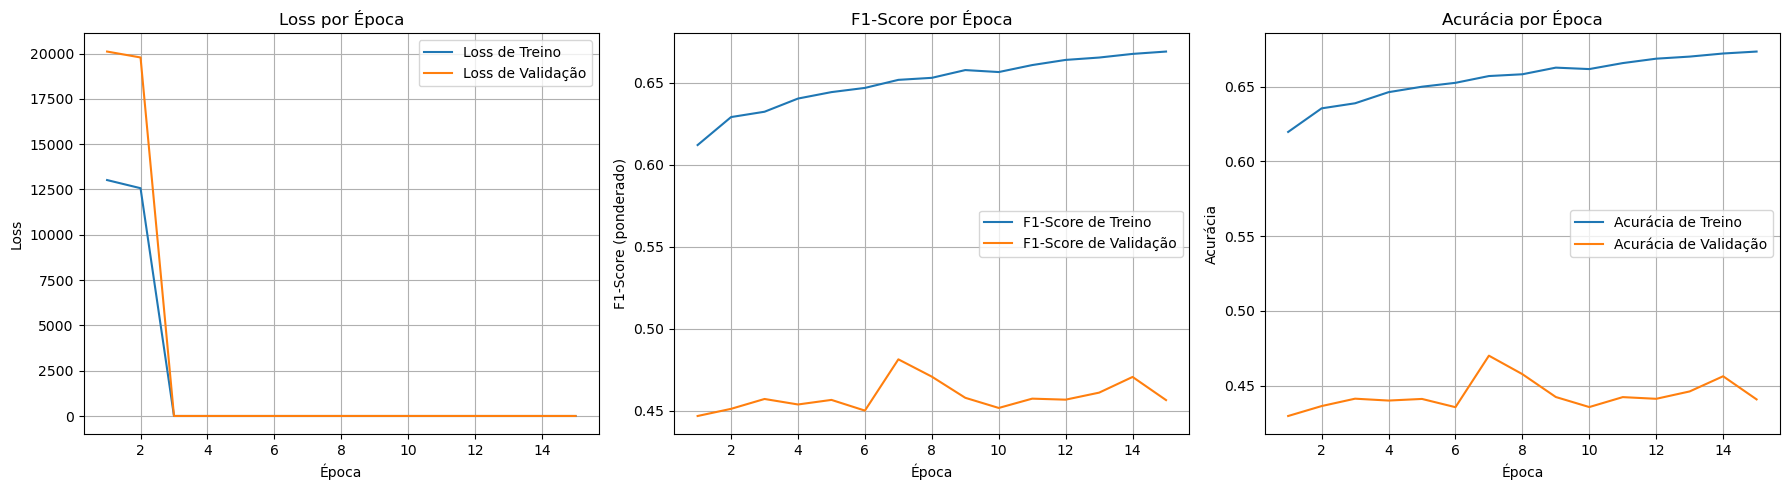

In [13]:
plot_metrics(train_losses, train_f1s, train_accuracies, val_losses, val_f1s, val_accuracies, NUM_EPOCHS_FINETUNE)

In [14]:
convnext_fine_results = evaluate_robustness(model, test_loader, noise_levels, "ConvNeXt")


--- Avaliando Robustez: ConvNeXt ---


Noise 0%: 100%|██████████| 100/100 [00:39<00:00,  2.52it/s]

Ruído: 0.0% -> Top-1: 59.37% | Top-5: 69.69%



Noise 2%: 100%|██████████| 100/100 [00:20<00:00,  4.80it/s]

Ruído: 2.0% -> Top-1: 53.29% | Top-5: 63.76%


...

Ruído: 5.0% -> Top-1: 43.56% | Top-5: 54.42%



Noise 10%: 100%|██████████| 100/100 [00:21<00:00,  4.65it/s]

Ruído: 10.0% -> Top-1: 27.59% | Top-5: 38.51%



Noise 15%: 100%|██████████| 100/100 [00:21<00:00,  4.60it/s]


Ruído: 15.0% -> Top-1: 15.55% | Top-5: 24.96%
